#### ***RAG***
   - ***RAG (Retrieval-Augmented Generation) improves LLM responses by retrieving relevant external knowledge before generating an answer.***
   -  ***A typical pipeline converts documents into embeddings, stores them in a vector database, retrieves the most relevant documents for a user's query, and passes them as context to the LLM.***
   - ***In LangGraph, RAG becomes more robust by using graph-based workflows with conditional routing, retries, document grading, memory, and validation, making it well suited for production Agentic AI applications.***

In [1]:
import warnings
warnings.filterwarnings("ignore")

from langchain_groq import ChatGroq
from langchain_google_genai import GoogleGenerativeAIEmbeddings,ChatGoogleGenerativeAI
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.tools import tool
from langgraph.graph import StateGraph,START,END 
from typing import Annotated,TypedDict
from langchain_core.messages import HumanMessage,BaseMessage
from langgraph.prebuilt import ToolNode,tools_condition

from dotenv import load_dotenv
load_dotenv()

d:\AIML_Engineer\AIML_Stack\Agentic_AI\venv\Lib\site-packages\langgraph\checkpoint\base\__init__.py:18: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


True

In [2]:
# Define Our Model
LLM = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.7
)

In [3]:
loader = PyPDFLoader("../notes/Genai_P1.pdf")
docs = loader.load()

In [4]:
print(docs)

[Document(metadata={'producer': 'PyPDF', 'creator': 'PyPDF', 'creationdate': '', 'source': '../notes/Genai_P1.pdf', 'total_pages': 33, 'page': 0, 'page_label': '1'}, page_content='Sheryians AI School 0\nGenerative A\nAkarsh Vya'), Document(metadata={'producer': 'PyPDF', 'creator': 'PyPDF', 'creationdate': '', 'source': '../notes/Genai_P1.pdf', 'total_pages': 33, 'page': 1, 'page_label': '2'}, page_content='Prerequisite\nSheryians AI schoo 0\nBefore starting there are things that you should know.\n\nPython Programming\nMachine Learning Fundamentals\nDeep Learning Concepts\nUnderstanding of Transformers\nBasic NLP (tokenization, embeddings'), Document(metadata={'producer': 'PyPDF', 'creator': 'PyPDF', 'creationdate': '', 'source': '../notes/Genai_P1.pdf', 'total_pages': 33, 'page': 2, 'page_label': '3'}, page_content='Sheryians AI schoo 0\nHere’s some important \nphases before \nstarting'), Document(metadata={'producer': 'PyPDF', 'creator': 'PyPDF', 'creationdate': '', 'source': '../note

In [5]:
len(docs)

33

In [6]:
# Text Splitter 
splitter = RecursiveCharacterTextSplitter(chunk_size=1000,chunk_overlap=70)
chunks = splitter.split_documents(docs)

In [7]:
len(chunks)

33

In [8]:
# embeddings = HuggingFaceEmbeddings(
#     model_name="BAAI/bge-small-en-v1.5"
# )
# vector_store = FAISS.from_documents(chunks,embeddings)
# vector_store.save_local("faiss_index")

In [9]:
embedds = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001"
)
vector_store = FAISS.from_documents(chunks, embedds)
vector_store.save_local("faiss_index")

In [10]:
vector_store

In [11]:
retriever = vector_store.as_retriever(search_type="similarity",search_kwargs={'k':3})

In [12]:
response = retriever.invoke("what is models")
print(response)

[Document(id='671a1228-8e54-42fc-a312-70b0b509716c', metadata={'producer': 'PyPDF', 'creator': 'PyPDF', 'creationdate': '', 'source': '../notes/Genai_P1.pdf', 'total_pages': 33, 'page': 18, 'page_label': '19'}, page_content='Model\nSheryians AI school 1\nModels are the core intelligence layer.\u2028\n They generate text, embeddings, or other outputs.\nThey connect your application to LLM providers like:\nOpenAI\nGoogle DeepMind\nAnthropi'), Document(id='b3cec5ef-1bb1-47e1-ab33-e357bc2faa5d', metadata={'producer': 'PyPDF', 'creator': 'PyPDF', 'creationdate': '', 'source': '../notes/Genai_P1.pdf', 'total_pages': 33, 'page': 19, 'page_label': '20'}, page_content='Model\nSheryians AI school 2\nIn practical Generative AI, there are mainly 3 important types \nof models\nChat / Language Models\nGenerate text\n Answer questions\n Write code\n Summarize conten\nEmbedding Models\nConvert text into \nnumbers (vectors)\nUsed in search & \nRAG\nHelp find similar \nconten\nMultimodal Models\nWork wi

In [13]:
@tool 
def rag_tool(query:str) -> str:
    """
    - Retrieve relevant information from the PDF document.
    - Use this tool when the user asks factual or conceptual questions.
    - that may be answered using the stored PDF documents.

    - Args:
        query: The question or search query used to retrieve PDF content.
    """
    docs = retriever.invoke(query)
    if not docs:
        return "no relevant result found in provided data."
    formatted_docs = []
    for i,doc in enumerate(docs,start=1):
        source = doc.metadata.get("source","unknown source")
        page = doc.metadata.get("page","unknown page")

        formatted_docs.append(
        f"Document {i}\n"
        f"Source: {source}\n"
        f"Page: {page}\n"
        f"Content: {doc.page_content}")
    return "\n\n".join(formatted_docs)

In [14]:
# Tool Binding
tools = [rag_tool]
llm_tool = LLM.bind_tools(tools)

In [15]:
from langgraph.graph.message import add_messages
# Define State 
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [16]:
# Graph Node 
def chat_node(state:ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_tool.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)

In [17]:
# Graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")  
chatbot = graph.compile()

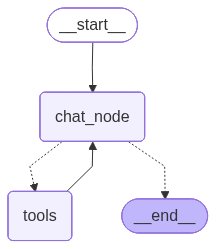

In [18]:
from IPython.display import Image
Image(chatbot.get_graph().draw_mermaid_png())

In [19]:
# Regular chat
result = chatbot.invoke({"messages": [HumanMessage(content="Hello")]})

print(result["messages"][-1].content)

Hello! How can I assist you today?


In [21]:
# Regular chat
result = chatbot.invoke({"messages": [HumanMessage(content="Using the pdf notes, models,chain,prompt template and indexs?")]})

print(result["messages"][-1].content)

Below is a concise “play‑book” that shows how the five pieces you mentioned – **PDF notes, models, chains, prompt templates, and indexes** – fit together to build a practical Generative‑AI (Gen‑AI) application.  
I’ve pulled the core definitions from the Sheryian AI School notes you provided and then wired them into a step‑by‑step workflow you can copy‑paste into a notebook or a small script.

---

## 1️⃣ What each piece means (quick recap)

| Piece | What the notes say | What it does in a pipeline |
|------|-------------------|----------------------------|
| **PDF notes** | Raw documents (PDFs, Word files, etc.) that contain the knowledge you want the LLM to use. | Source data that will be ingested, chunked, and stored in an **index** for retrieval. |
| **Model** | “Core intelligence layer” – can be a **Chat/Language model**, **Embedding model**, or **Multimodal model** (Gen‑AI notes, p. 18‑19). | Generates the final answer (chat model) and creates vector embeddings (embedding model) 